<a href="https://colab.research.google.com/github/MadAcolyte/mitre-attack-threat-group-similarity/blob/main/1.5/cnn_Transfer_learning_Intel.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Transfer learning — Intel Image Classification

Adapted from `cnn_Transfer_learning.ipynb`: classify six types of scenes instead
of CIFAR-10 objects. All explanations and instructions are in English.

**Dataset:** [Intel Image Classification on Kaggle](https://www.kaggle.com/datasets/puneet6060/intel-image-classification).
Classes: `buildings`, `forest`, `glacier`, `mountain`, `sea`, `street`.

**How to run:** open this notebook in Google Colab, select a GPU runtime, and run
the cells in order. Internet access is required to download the data and ImageNet weights.
You can also use a local Jupyter environment supported by TensorFlow.
Results are saved in the `intel_results` folder in the current environment.

We compare two models: one without augmentation and one with augmentation.
Both start from the same weights and use the same maximum number of epochs.
The EfficientNet backbone remains frozen; only the classifier is trained.
This notebook does not fine-tune the backbone.

Instead of the TensorFlow Hub layer with ImageNet-21k weights, we use
`tf.keras.applications.EfficientNetV2B1` with ImageNet weights (1000 classes).
This lets us use a single `tf.keras` API and the `.keras` model format.
Results should not be compared directly with the original notebook because
both the dataset and the source of pretrained weights have changed.

In [1]:
%pip install -q tensorflow kagglehub matplotlib scikit-learn pillow

In [7]:
from pathlib import Path
import json
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, ConfusionMatrixDisplay

SEED = 42
IMAGE_SHAPE = (240, 240)
BATCH_SIZE = 32  # Reduce to 16 or 8 if GPU memory runs out.
EPOCHS = 10
VALIDATION_FRACTION = 0.20
CLASS_NAMES = ['buildings', 'forest', 'glacier', 'mountain', 'sea', 'street']
RESULTS_DIR = Path('intel_results')
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
keras.utils.set_random_seed(SEED)
print('TensorFlow:', tf.__version__)
print('GPU:', tf.config.list_physical_devices('GPU'))

TensorFlow: 2.21.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 1. Download and locate the dataset

By default, `kagglehub` downloads the dataset. If you already have an extracted copy,
set `LOCAL_DATA_DIR` to its folder, for example `r'D:\data\intel-image-classification'`.
In Kaggle Notebooks, you can use `/kaggle/input/intel-image-classification`.
If Kaggle requires authentication, run `import kagglehub; kagglehub.login()` in
a separate cell and retry, or download the ZIP from the dataset page and extract it manually.

We use `seg_train` for training and validation, and reserve `seg_test` for the final
evaluation. The optional `seg_pred` folder contains unlabeled images and cannot
be used to calculate accuracy.

In [8]:
LOCAL_DATA_DIR = None  # Set to your extracted dataset folder if available.

if LOCAL_DATA_DIR is None:
    import kagglehub
    DATA_ROOT = Path(kagglehub.dataset_download('puneet6060/intel-image-classification'))
else:
    DATA_ROOT = Path(LOCAL_DATA_DIR).expanduser()
if not DATA_ROOT.is_dir():
    raise FileNotFoundError(f'Directory does not exist: {DATA_ROOT}')

def find_labeled_directory(root, name):
    candidates = [root / name, root / name / name]
    candidates += sorted(root.rglob(name))
    for candidate in candidates:
        if candidate.is_dir() and all((candidate / c).is_dir() for c in CLASS_NAMES):
            return candidate
    raise FileNotFoundError(f'Could not find {name} with all six class folders under {root}')

TRAIN_DIR = find_labeled_directory(DATA_ROOT, 'seg_train')
TEST_DIR = find_labeled_directory(DATA_ROOT, 'seg_test')
print('Training:', TRAIN_DIR)
print('Test:', TEST_DIR)

Using Colab cache for faster access to the 'intel-image-classification' dataset.
Training: /kaggle/input/intel-image-classification/seg_train/seg_train
Test: /kaggle/input/intel-image-classification/seg_test/seg_test


## 2. Split and load the images

We hold out 20% of `seg_train` for validation, preserving class proportions with
`stratify`. Images are loaded in batches to avoid keeping the entire dataset in RAM.
Each image is converted to RGB and resized to 240 × 240 pixels.
Pixel values remain in the **0–255** range because EfficientNetV2 includes its own
normalization. Do not divide the pixels by 255 before passing them to the model.

In [9]:
EXTENSIONS = {'.jpg', '.jpeg', '.png', '.bmp'}

def collect_images(directory):
    paths, labels = [], []
    for label, name in enumerate(CLASS_NAMES):
        class_files = sorted(p for p in (directory / name).rglob('*')
                             if p.is_file() and p.suffix.lower() in EXTENSIONS)
        if not class_files:
            raise ValueError(f'No images found for class: {name}')
        paths.extend(str(p) for p in class_files)
        labels.extend([label] * len(class_files))
    return np.array(paths), np.array(labels, dtype=np.int32)

all_train_paths, all_train_labels = collect_images(TRAIN_DIR)
test_paths, test_labels = collect_images(TEST_DIR)
train_paths, val_paths, train_labels, val_labels = train_test_split(
    all_train_paths, all_train_labels, test_size=VALIDATION_FRACTION,
    stratify=all_train_labels, random_state=SEED,
)
assert not (set(train_paths) & set(val_paths))
assert not ((set(train_paths) | set(val_paths)) & set(test_paths))
for name, labels in [('Training', train_labels), ('Validation', val_labels), ('Test', test_labels)]:
    print(f'{name}: {len(labels)} images; class counts: {np.bincount(labels, minlength=6)}')

def load_image(path, label):
    image = tf.io.decode_image(tf.io.read_file(path), channels=3, expand_animations=False)
    image.set_shape([None, None, 3])
    image = tf.image.resize(image, IMAGE_SHAPE)
    return image, label

def make_dataset(paths, labels, training=False):
    ds = tf.data.Dataset.from_tensor_slices((paths, labels))
    if training:
        ds = ds.shuffle(len(paths), seed=SEED, reshuffle_each_iteration=True)
    ds = ds.map(load_image, num_parallel_calls=tf.data.AUTOTUNE)
    return ds.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

val_ds = make_dataset(val_paths, val_labels)
test_ds = make_dataset(test_paths, test_labels)  # Keep a fixed order for reports and plots.

Training: 11227 images; class counts: [1753 1817 1923 2009 1819 1906]
Validation: 2807 images; class counts: [438 454 481 503 455 476]
Test: 3000 images; class counts: [437 474 553 525 510 501]


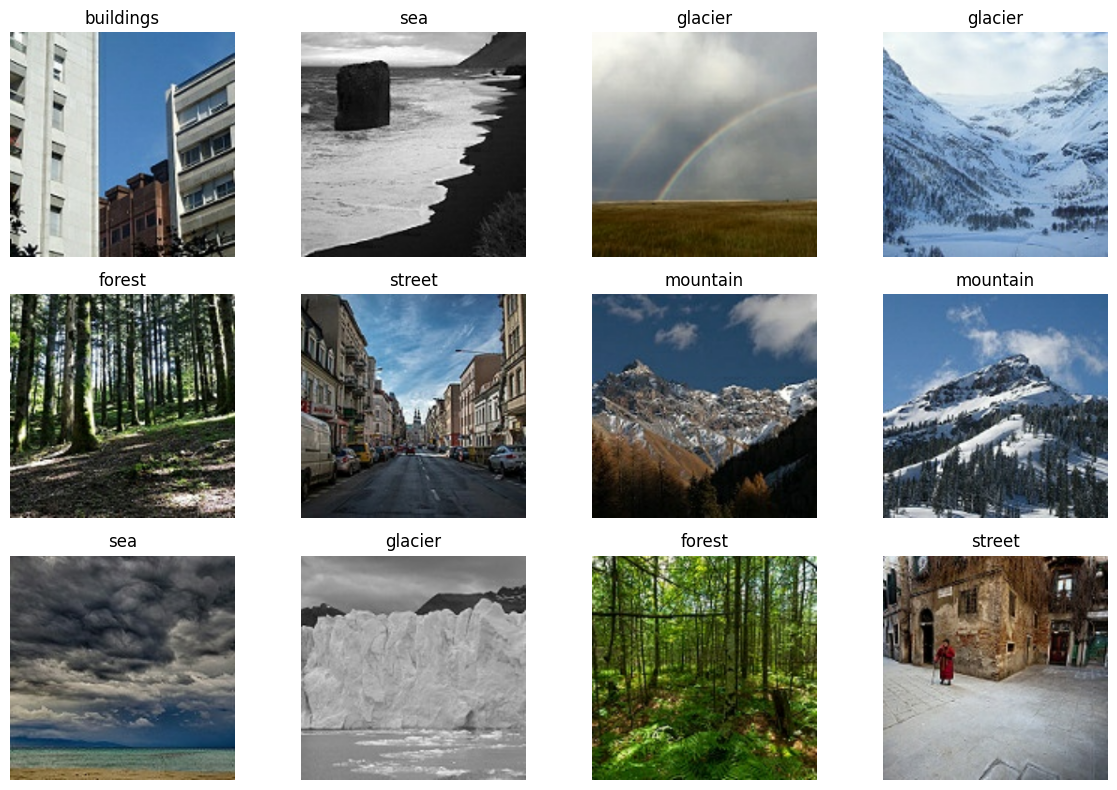

In [10]:
images, labels = next(iter(make_dataset(train_paths, train_labels)))
plt.figure(figsize=(12, 8))
for i in range(min(12, len(images))):
    plt.subplot(3, 4, i + 1)
    plt.imshow(images[i].numpy().clip(0, 255).astype('uint8'))
    plt.title(CLASS_NAMES[int(labels[i])])
    plt.axis('off')
plt.tight_layout()
plt.show()

## 3. Model and data augmentation

The frozen EfficientNetV2B1 extracts features, and a Dense layer learns the six classes.
Random augmentation is active during training and disabled during validation and prediction.
We avoid vertical flips so that landscapes are not turned upside down.
Both variants receive identical initial backbone and classifier weights.

In [11]:
def build_model(augment=False):
    augmentation = keras.Sequential([
        layers.RandomFlip('horizontal', seed=SEED),
        layers.RandomRotation(0.05, seed=SEED + 1),
        layers.RandomTranslation(0.1, 0.1, seed=SEED + 2),
        layers.RandomZoom(0.1, seed=SEED + 3),
        layers.RandomBrightness(0.1, value_range=(0, 255), seed=SEED + 4),
    ], name='augmentation')
    base = keras.applications.EfficientNetV2B1(
        include_top=False, weights='imagenet', input_shape=(*IMAGE_SHAPE, 3),
        pooling='avg', include_preprocessing=True,
    )
    base.trainable = False
    inputs = keras.Input(shape=(*IMAGE_SHAPE, 3), name='image')
    x = augmentation(inputs) if augment else inputs
    x = base(x, training=False)
    outputs = layers.Dense(
        len(CLASS_NAMES), activation='softmax',
        kernel_initializer=keras.initializers.GlorotUniform(seed=SEED), name='classifier',
    )(x)
    model = keras.Model(inputs, outputs, name='intel_augmented' if augment else 'intel_baseline')
    model.compile(optimizer=keras.optimizers.Adam(1e-3),
                  loss='sparse_categorical_crossentropy', metrics=['accuracy'])
    return model

def training_callbacks(name):
    return [
        keras.callbacks.ModelCheckpoint(
            str(RESULTS_DIR / f'{name}.keras'), monitor='val_loss', save_best_only=True),
        keras.callbacks.EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True),
    ]

baseline_model = build_model(augment=False)
initial_weights = baseline_model.get_weights()
baseline_model.summary()

Model: "intel_baseline"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ image (InputLayer)              │ (None, 240, 240, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetv2-b1 (Functional)  │ (None, 1280)           │     6,931,124 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ classifier (Dense)              │ (None, 6)              │         7,686 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,938,810 (26.47 MB)

 Trainable params: 7,686 (30.02 KB)

 Non-trainable params: 6,931,124 (26.44 MB)

## 4. Training without augmentation

In [12]:
keras.utils.set_random_seed(SEED)
baseline_history = baseline_model.fit(
    make_dataset(train_paths, train_labels, training=True),
    validation_data=val_ds, epochs=EPOCHS, callbacks=training_callbacks('baseline'),
)
baseline_model = keras.models.load_model(RESULTS_DIR / 'baseline.keras')

Epoch 1/10
351/351 ━━━━━━━━━━━━━━━━━━━━ 102s 196ms/step - accuracy: 0.8837 - loss: 0.3613 - val_accuracy: 0.9145 - val_loss: 0.2392
Epoch 2/10
351/351 ━━━━━━━━━━━━━━━━━━━━ 25s 71ms/step - accuracy: 0.9252 - loss: 0.2171 - val_accuracy: 0.9170 - val_loss: 0.2168
Epoch 3/10
351/351 ━━━━━━━━━━━━━━━━━━━━ 24s 68ms/step - accuracy: 0.9336 - loss: 0.1926 - val_accuracy: 0.9198 - val_loss: 0.2077
Epoch 4/10
351/351 ━━━━━━━━━━━━━━━━━━━━ 41s 67ms/step - accuracy: 0.9350 - loss: 0.1806 - val_accuracy: 0.9248 - val_loss: 0.2039
Epoch 5/10
351/351 ━━━━━━━━━━━━━━━━━━━━ 25s 71ms/step - accuracy: 0.9405 - loss: 0.1687 - val_accuracy: 0.9234 - val_loss: 0.1985
Epoch 6/10
351/351 ━━━━━━━━━━━━━━━━━━━━ 23s 65ms/step - accuracy: 0.9423 - loss: 0.1609 - val_accuracy: 0.9230 - val_loss: 0.2007
Epoch 7/10
351/351 ━━━━━━━━━━━━━━━━━━━━ 24s 69ms/step - accuracy: 0.9444 - loss: 0.1574 - val_accuracy: 0.9259 - val_loss: 0.1968
Epoch 8/10
351/351 ━━━━━━━━━━━━━━━━━━━━ 24s 68ms/step - accuracy: 0.9443 - loss: 0.1540 

## 5. Training with augmentation

We create a second model from the same starting point. This comparison separates
the effect of augmentation from the effect of training the first model for more epochs.

In [13]:
keras.utils.set_random_seed(SEED)
augmented_model = build_model(augment=True)
augmented_model.set_weights(initial_weights)
del initial_weights
augmented_history = augmented_model.fit(
    make_dataset(train_paths, train_labels, training=True),
    validation_data=val_ds, epochs=EPOCHS, callbacks=training_callbacks('augmented'),
)
augmented_model = keras.models.load_model(RESULTS_DIR / 'augmented.keras')

Epoch 1/10
351/351 ━━━━━━━━━━━━━━━━━━━━ 66s 139ms/step - accuracy: 0.8545 - loss: 0.4312 - val_accuracy: 0.9081 - val_loss: 0.2588
Epoch 2/10
351/351 ━━━━━━━━━━━━━━━━━━━━ 44s 124ms/step - accuracy: 0.9048 - loss: 0.2691 - val_accuracy: 0.9127 - val_loss: 0.2333
Epoch 3/10
351/351 ━━━━━━━━━━━━━━━━━━━━ 44s 126ms/step - accuracy: 0.9129 - loss: 0.2426 - val_accuracy: 0.9141 - val_loss: 0.2252
Epoch 4/10
351/351 ━━━━━━━━━━━━━━━━━━━━ 44s 125ms/step - accuracy: 0.9189 - loss: 0.2290 - val_accuracy: 0.9227 - val_loss: 0.2132
Epoch 5/10
351/351 ━━━━━━━━━━━━━━━━━━━━ 83s 127ms/step - accuracy: 0.9190 - loss: 0.2223 - val_accuracy: 0.9252 - val_loss: 0.2096
Epoch 6/10
351/351 ━━━━━━━━━━━━━━━━━━━━ 42s 121ms/step - accuracy: 0.9208 - loss: 0.2150 - val_accuracy: 0.9223 - val_loss: 0.2105
Epoch 7/10
351/351 ━━━━━━━━━━━━━━━━━━━━ 43s 123ms/step - accuracy: 0.9225 - loss: 0.2114 - val_accuracy: 0.9263 - val_loss: 0.2118
Epoch 8/10
351/351 ━━━━━━━━━━━━━━━━━━━━ 44s 125ms/step - accuracy: 0.9257 - loss: 0

## 6. Learning curves and model selection using validation data

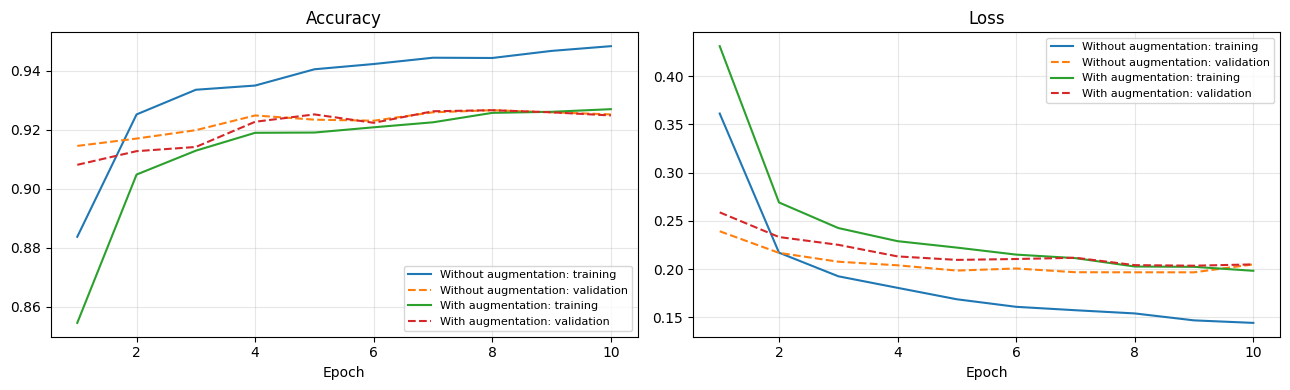

Validation results: {'baseline': {'accuracy': 0.9258995652198792, 'loss': 0.1966801881790161}, 'augmented': {'accuracy': 0.9258995652198792, 'loss': 0.20353268086910248}}
Selected model (lowest validation loss): baseline


In [14]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for name, history in [('Without augmentation', baseline_history), ('With augmentation', augmented_history)]:
    epochs = range(1, len(history.history['loss']) + 1)
    axes[0].plot(epochs, history.history['accuracy'], label=f'{name}: training')
    axes[0].plot(epochs, history.history['val_accuracy'], '--', label=f'{name}: validation')
    axes[1].plot(epochs, history.history['loss'], label=f'{name}: training')
    axes[1].plot(epochs, history.history['val_loss'], '--', label=f'{name}: validation')
for ax, title in zip(axes, ['Accuracy', 'Loss']):
    ax.set(title=title, xlabel='Epoch')
    ax.legend(fontsize=8)
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(RESULTS_DIR / 'learning_curves.png', dpi=150)
plt.show()

models = {'baseline': baseline_model, 'augmented': augmented_model}
validation_scores = {name: model.evaluate(val_ds, return_dict=True, verbose=0)
                     for name, model in models.items()}
best_name = min(validation_scores, key=lambda name: validation_scores[name]['loss'])
best_model = models[best_name]
print('Validation results:', validation_scores)
print('Selected model (lowest validation loss):', best_name)
best_model.save(RESULTS_DIR / 'intel_best.keras')

## 7. Final evaluation on the test set

We evaluate both variants for comparison; the model to use has already been selected
using validation data. Do not tune parameters based on test results.
The classification report and confusion matrix describe the selected model.
Results are generated after training; this notebook contains no predefined accuracy values.

baseline: test accuracy = 0.9290, test loss = 0.1855
augmented: test accuracy = 0.9223, test loss = 0.2048
              precision    recall  f1-score   support

   buildings       0.94      0.92      0.93       437
      forest       1.00      1.00      1.00       474
     glacier       0.87      0.88      0.88       553
    mountain       0.89      0.86      0.88       525
         sea       0.97      0.98      0.97       510
      street       0.92      0.95      0.94       501

    accuracy                           0.93      3000
   macro avg       0.93      0.93      0.93      3000
weighted avg       0.93      0.93      0.93      3000



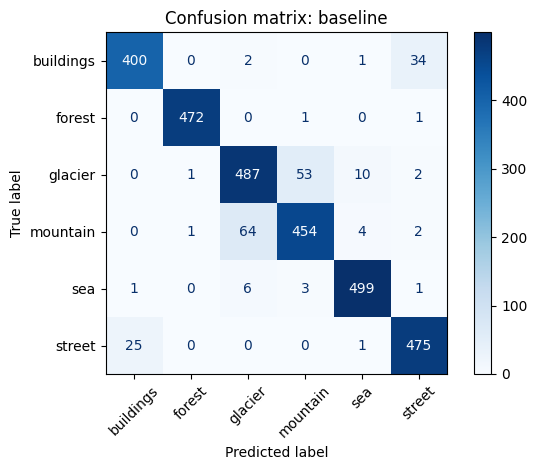

874

In [15]:
test_scores = {name: model.evaluate(test_ds, return_dict=True, verbose=0)
               for name, model in models.items()}
for name, scores in test_scores.items():
    print(f"{name}: test accuracy = {scores['accuracy']:.4f}, test loss = {scores['loss']:.4f}")

probabilities = best_model.predict(test_ds, verbose=0)
predictions = probabilities.argmax(axis=1)
report = classification_report(test_labels, predictions, labels=range(len(CLASS_NAMES)),
                               target_names=CLASS_NAMES, zero_division=0)
print(report)
(RESULTS_DIR / 'classification_report.txt').write_text(report, encoding='utf-8')
ConfusionMatrixDisplay.from_predictions(
    test_labels, predictions, labels=range(len(CLASS_NAMES)),
    display_labels=CLASS_NAMES, cmap='Blues', xticks_rotation=45,
)
plt.title(f'Confusion matrix: {best_name}')
plt.tight_layout()
plt.savefig(RESULTS_DIR / 'confusion_matrix.png', dpi=150)
plt.show()

metadata = {
    'dataset': 'puneet6060/intel-image-classification',
    'class_names': CLASS_NAMES, 'image_shape': list(IMAGE_SHAPE),
    'pixel_range': [0, 255], 'seed': SEED, 'tensorflow_version': tf.__version__,
    'batch_size': BATCH_SIZE, 'max_epochs': EPOCHS,
    'split_sizes': {'train': len(train_paths), 'validation': len(val_paths), 'test': len(test_paths)},
    'best_model': best_name, 'validation': validation_scores, 'test': test_scores,
}
(RESULTS_DIR / 'metadata.json').write_text(
    json.dumps(metadata, indent=2, ensure_ascii=False), encoding='utf-8')

## 8. Sample predictions — green titles indicate correct predictions

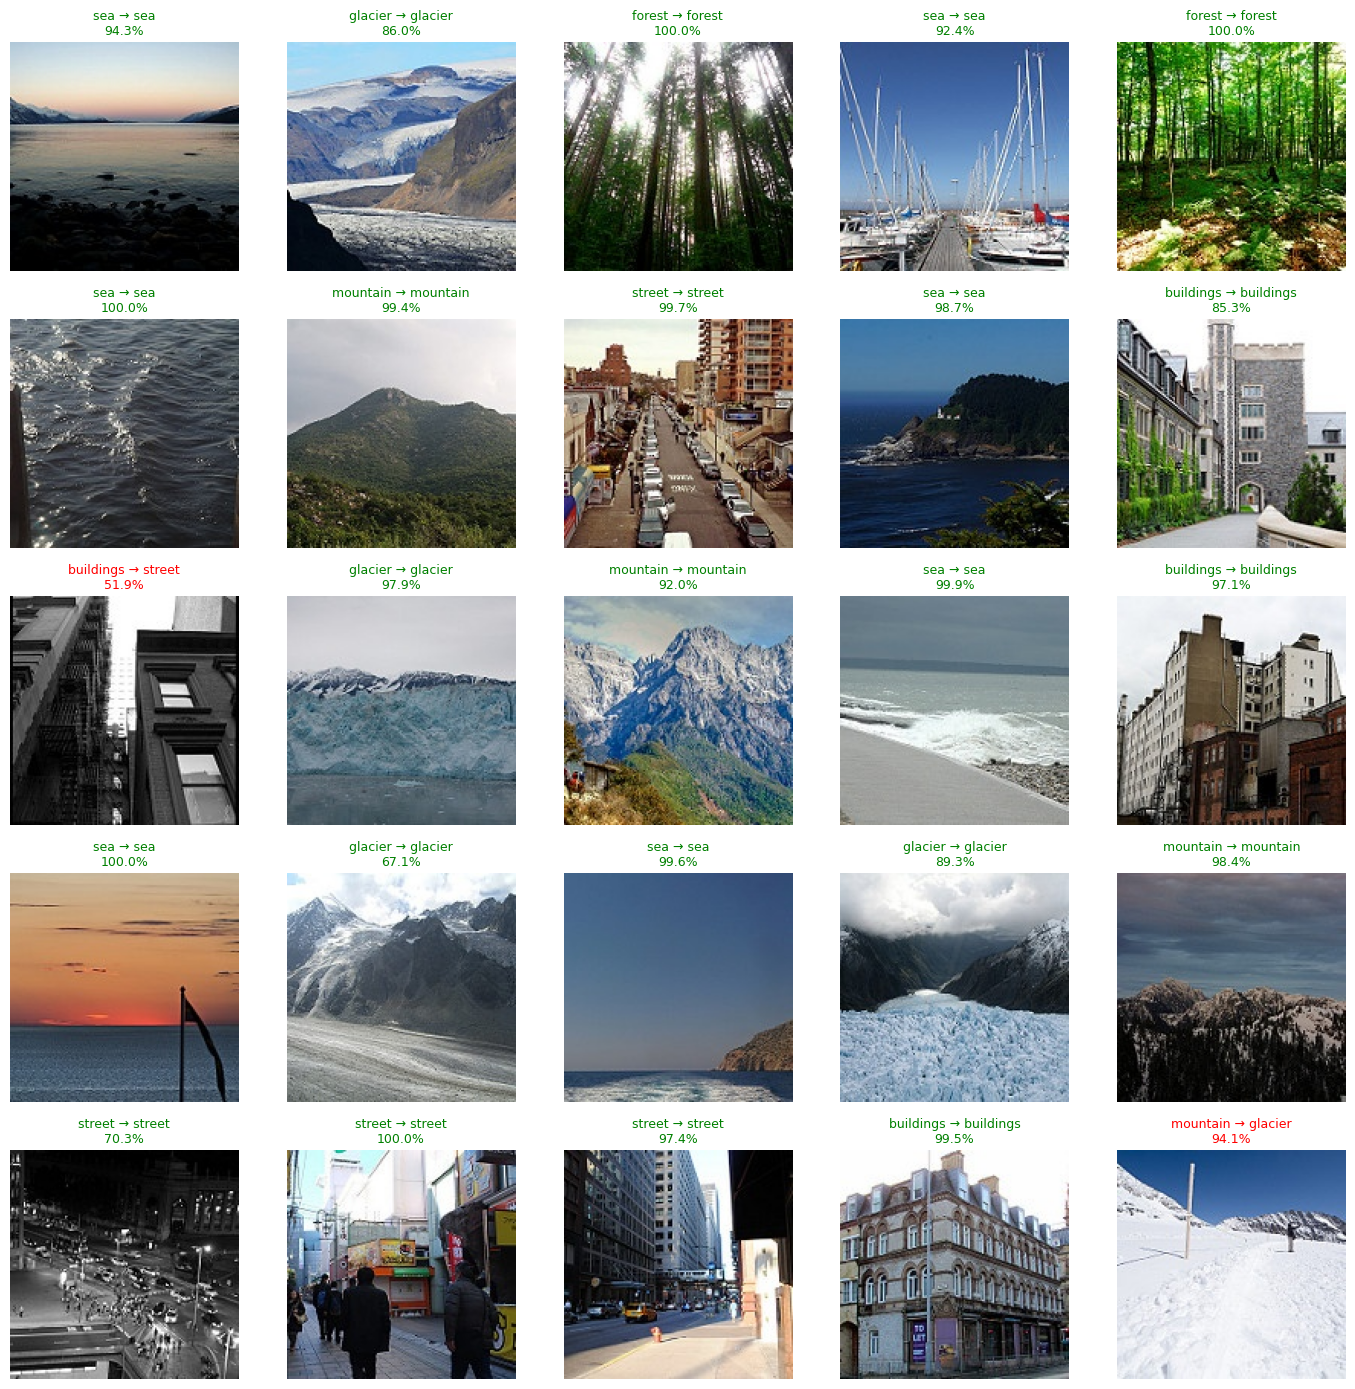

In [16]:
from PIL import Image

rng = np.random.default_rng(SEED)
indices = rng.choice(len(test_paths), size=min(25, len(test_paths)), replace=False)
plt.figure(figsize=(14, 14))
for i, index in enumerate(indices):
    plt.subplot(5, 5, i + 1)
    with Image.open(test_paths[index]) as image:
        plt.imshow(image.convert('RGB'))
    actual, predicted = int(test_labels[index]), int(predictions[index])
    confidence = probabilities[index, predicted]
    plt.title(f'{CLASS_NAMES[actual]} → {CLASS_NAMES[predicted]}\n{confidence:.1%}',
              color='green' if actual == predicted else 'red', fontsize=9)
    plt.axis('off')
plt.tight_layout()
plt.savefig(RESULTS_DIR / 'sample_predictions.png', dpi=150)
plt.show()

## 9. Use the saved model on your own image (optional)

After restarting the environment, run the imports and provide the files
`intel_best.keras` and `metadata.json`. In Colab, download these files before
ending the session. Set `MY_IMAGE_PATH` to classify your own image.

In [17]:
MY_IMAGE_PATH = None  # For example: '/content/my_image.jpg'

if MY_IMAGE_PATH is not None:
    saved_metadata = json.loads((RESULTS_DIR / 'metadata.json').read_text(encoding='utf-8'))
    loaded_model = keras.models.load_model(RESULTS_DIR / 'intel_best.keras')
    image = keras.utils.load_img(MY_IMAGE_PATH, target_size=tuple(saved_metadata['image_shape']))
    batch = np.expand_dims(keras.utils.img_to_array(image), axis=0)
    scores = loaded_model.predict(batch, verbose=0)[0]
    predicted = int(scores.argmax())
    plt.imshow(image)
    plt.title(f"{saved_metadata['class_names'][predicted]}: {scores[predicted]:.1%}")
    plt.axis('off')
    plt.show()

## Sources and interpretation

- [Intel Image Classification dataset](https://www.kaggle.com/datasets/puneet6060/intel-image-classification)
- [EfficientNetV2 and its expected pixel range](https://keras.io/api/applications/efficientnet_v2/)
- [Download datasets with kagglehub](https://github.com/Kaggle/kagglehub)

Augmentation can improve generalization but does not guarantee a higher score.
Compare training and validation accuracy, and inspect confusion between similar
scenes, such as mountains and glaciers. A single split and random seed represent
one experiment; a more reliable comparison requires multiple runs.